<a href="https://colab.research.google.com/github/DrDourado/ME_640_Optimum_Design_Fall_2026/blob/main/ME_640_09_RBDO_Benchmarks_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ME 640 — Reliability-Based Design Optimization
## Lecture 2 — FORM-Based RBDO and Benchmark Applications

### Objectives
Formulate RBDO; solve analytical and structural benchmark-style problems; understand active reliability constraints, cost–reliability tradeoffs, and double-loop computation.

The examples use problem classes common in the RBDO literature. Numerical values are streamlined for instruction where noted.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import minimize
np.random.seed(640)
plt.rcParams["figure.figsize"]=(7,5)

# 1. Classical formulation
$$
\min_{\mathbf d} C(\mathbf d)
\quad\mathrm{s.t.}\quad
\beta_j(\mathbf d)\ge\beta_j^{target}.
$$
For FORM,
$$
\beta_j(\mathbf d)=\min_{\mathbf u}\|\mathbf u\|
\quad\mathrm{s.t.}\quad G_j(\mathbf d,\mathbf u)=0.
$$
Hence reliability analysis is an optimization nested inside design optimization.

# 2. Benchmark-style tension member
Design area $A$, uncertain yield strength $Y$, uncertain force $P$:
$$
\min A, \qquad g(A,Y,P)=AY-P
$$
For independent normals,
$$
\beta(A)=\frac{A\mu_Y-\mu_P}{\sqrt{A^2\sigma_Y^2+\sigma_P^2}}.
$$
Require $P_f\le 1/10000$.

In [2]:
Prob_of_failure=1e-4
beta_required = -norm.ppf(1e-4)
print("beta_required = ", beta_required)

beta_required =  3.7190164854556804


Nominal boundary A = 1.6  beta = 0.0  Pf = 50.0 %
RBDO A = 2.466931128741916  beta = 3.720059664556284  Pf = 0.009958785973556044 %


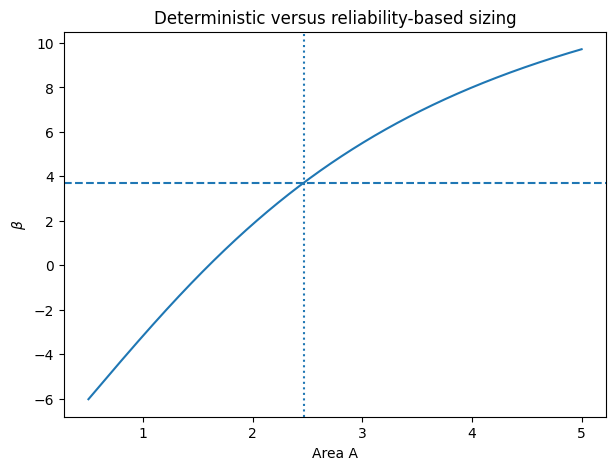

In [3]:
muY,sY,muP,sP=250,15,400,45
def betaA(A): return (A*muY-muP)/np.sqrt((A*sY)**2+sP**2)
A=np.linspace(.5,5,15000); vals=np.array([betaA(a) for a in A])
Ast=A[vals>=beta_required][0]; Adet=muP/muY
print("Nominal boundary A =",Adet," beta =",betaA(Adet), " Pf =",norm.cdf(-betaA(Adet))*100,"%")
print("RBDO A =",Ast," beta =",betaA(Ast), " Pf =",norm.cdf(-betaA(Ast))*100,"%")
fig,ax=plt.subplots();ax.plot(A,vals);ax.axhline(beta_required,ls="--");ax.axvline(Ast,ls=":")
ax.set(xlabel="Area A",ylabel=r"$\beta$",title="Deterministic versus reliability-based sizing");plt.show()

The deterministic boundary $A=\mu_P/\mu_Y$ has essentially zero mean safety margin. RBDO moves the solution into a region where the probability of violating the constraint is controlled.

# 3. Cost–reliability tradeoff
Reliability targets are design-policy choices. Increasing $\beta_{target}$ usually increases mass/cost. Solve the same problem over a range of targets to visualize this tradeoff.

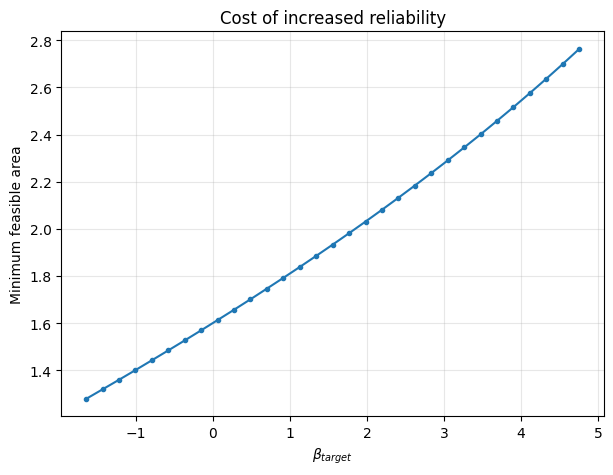

In [4]:
Min_Prob_failure,Max_Prob_failure = 0.95, 1/1000000
Min_beta,Max_beta = -norm.ppf(Min_Prob_failure), -norm.ppf(Max_Prob_failure)
targets=np.linspace(Min_beta,Max_beta,31); areas=[]
for bt in targets:
    ok=A[vals>=bt]; areas.append(ok[0] if len(ok) else np.nan)
fig,ax=plt.subplots();ax.plot(targets,areas,marker="o",ms=3)
ax.set(xlabel=r"$\beta_{target}$",ylabel="Minimum feasible area",title="Cost of increased reliability")
ax.grid(alpha=.3);plt.show()

# 4. Cantilever beam benchmark class
Cantilever beams are common RBDO benchmarks. For rectangular width $b$, height $h$, length $L$, tip load $P$, A simple objective is:
$$
\min_{b,h} bh.
$$
Stress:
$$
\sigma_{\max}=\frac{6PL}{bh^2},
\qquad
g_\sigma=Y-\frac{6PL}{bh^2}.
$$
Deflection:
$$
\delta=\frac{4PL^3}{Ebh^3},
\qquad
g_\delta=\delta_{\max}-\delta.
$$

Assuming, $L=1$, $P\sim\mathcal N(\mu_P = 1000,\sigma_P^2 = 14400)$ , $Y\sim\mathcal N(\mu_Y = 180MPa,\sigma_Y^2 = 144*10^{12}Pa)$ , $E\sim\mathcal N(\mu_E = 70000MPa,\sigma_E^2 = 12.25*10^{18}Pa)$, and $δ_{max}=0.008$, find the optimal beam for an acceptable probability of failure $P_f \le 1/100000$

In [5]:
beta_target = -norm.ppf(1/100000)
print("beta_target = ", beta_target)
L=1.; muP,sP=1000,np.sqrt(14400); muY,sY=180e6,np.sqrt(144e12); muE,sE=70e9,np.sqrt(12.25e18); dmax=.008

beta_target =  4.264890793922825


In [6]:
# Helper functions

# Beam objective function
def obj(z): return z[0]*z[1]

# Stress limit function
def bs(b,h):
    k=6*L/(b*h*h); return (muY-k*muP)/np.sqrt(sY**2+(k*sP)**2)

# Deflection limit function
def bd(b,h):
 K=4*L**3/(b*h**3); dm=K*muP/muE
 sd=np.sqrt((K/muE*sP)**2+(-K*muP/muE**2*sE)**2)
 return (dmax-dm)/sd

In [7]:
# Using scipy.minimize to determine solution
cons=[{"type":"ineq","fun":lambda z:bs(*z)-beta_target},{"type":"ineq","fun":lambda z:bd(*z)-beta_target}]
rr=minimize(obj,[.06,.12],bounds=[(.02,.12),(.04,.20)],constraints=cons,method="SLSQP")
print("b,h =",rr.x," area =",obj(rr.x)," beta stress =",bs(*rr.x)," beta deflection =",bd(*rr.x))

b,h = [0.02      0.0821959]  area = 0.0016439179503442477  beta stress = 10.327328614448367  beta deflection = 4.268626611804067


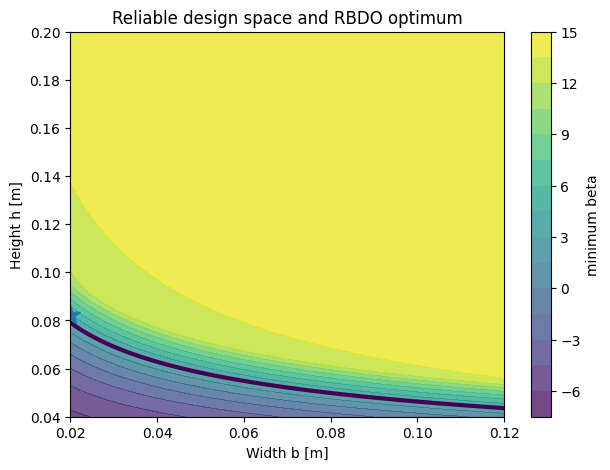

In [8]:
b=np.linspace(.02,.12,100);h=np.linspace(.04,.20,110);B,H=np.meshgrid(b,h)
Z=np.minimum(np.vectorize(bs)(B,H),np.vectorize(bd)(B,H))
fig,ax=plt.subplots();cf=ax.contourf(B,H,Z,levels=20,alpha=.75);plt.colorbar(cf,ax=ax,label="minimum beta")
ax.contour(B,H,Z,levels=[3],linewidths=3);ax.plot(*rr.x,"*",ms=15)
ax.set(xlabel="Width b [m]",ylabel="Height h [m]",title="Reliable design space and RBDO optimum");plt.show()

# 5. Why the optimum often lies on a reliability boundary
If larger dimensions increase both cost and reliability, extra reliability beyond the target may have no objective benefit. Consequently, at least one reliability constraint is often active:
$$
\beta_j(\mathbf d^*)\approx\beta_j^{target}.
$$
This is analogous to active deterministic constraints, but the boundary now represents a probabilistic safety requirement.

# 6. Double-loop computation
For nonlinear constraints:
$$
\beta(\mathbf d)=\min_{\mathbf u}\|\mathbf u\|\;\;\mathrm{s.t.}\;\;G(\mathbf d,\mathbf u)=0.
$$
The outer optimizer changes $\mathbf d\$; every candidate can trigger an inner MPP search. This motivates double-loop, decoupled, single-loop, and surrogate-assisted strategies.

### Verification checklist
- recompute reliability at the final design;
- compare FORM with simulation where practical;
- inspect nonlinearity and possible multiple MPPs;
- test distribution assumptions;
- confirm the target reliability is appropriate.

### Discussion
1. Why does deterministic feasibility not imply reliability?
2. Why do RBDO optima often activate a reliability constraint?
3. What makes the double loop expensive?
4. What could make FORM inaccurate even if optimization converges?